# Couple representation predicts first-rule learning

For each `first_pattern` or `first_position` session, Couple Pattern/Position similarity is computed with the canonical `similarity_analysis.ipynb` method. `SIMILARITY_SOURCE` selects the nearest earlier standalone Couple session or the Couple block in the first-rule file.

The optional representation index is

$$
I_{\mathrm{sim}}=\frac{S_{\mathrm{pattern}}-S_{\mathrm{position}}}{S_{\mathrm{pattern}}+S_{\mathrm{position}}}.
$$

## Behavior

`TRIAL_SELECTION="all"` uses C1/C3/C5 destination trials. `"novel_only"` removes familiar C3 tracks (`ACB`, `BCA`) and renumbers C1/C5 trials, so all behavioral clocks use only selected trials. Correct and `NoReward` count as correct; FalseAlarm and Miss count as incorrect.

A forward 10-trial accuracy is

$$
A_t=\frac{1}{10}\sum_{j=t}^{t+9}c_j.
$$

If the first window is at or above `ACCURACY_THRESHOLD` (default 0.8), the animal is defined as learning immediately and assigned the finite `LEARNING_RATE_MAX`. Otherwise the rising exponential is fitted to all windows:

$$
\widehat A(x)=A_0+(1-A_0)q\left(1-e^{-kx}\right).
$$

A normal fitted rate is accepted; only a fitted value above `LEARNING_RATE_MAX` is clipped. Both clipped and raw rates are saved.

`trials_to_threshold` is the selected-trial count at the end of the first 10-trial window reaching `ACCURACY_THRESHOLD`. If never reached it is marked censored and left missing.

## Rule-specific relationship plots

Pattern-transition and Position-transition sessions are fitted and plotted separately, without sign transformations. Choose:

- `PLOT_X`: `"pattern_similarity"`, `"position_similarity"`, or `"similarity_bias_index"`;
- `PLOT_Y`: `"learning_rate"` or `"trials_to_threshold"`.


In [50]:
from __future__ import annotations

from pathlib import Path
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import least_squares


def find_repo_root(start: str | Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "setup.py").exists() and (candidate / "src").exists():
            return candidate
        nested = candidate / "ZhaoLab-analysis-python"
        if (nested / "setup.py").exists() and (nested / "src").exists():
            return nested
    raise FileNotFoundError("Cannot locate repository root.")


REPO_ROOT = find_repo_root()
SRC_ROOT = REPO_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from HPC_2P_analysis.utils.config import (  # noqa: E402
    get_data_behavior_type,
    get_data_track_type,
    get_itr_index,
    select_files,
)
from HPC_2P_analysis.utils.loadData import load_screen_data  # noqa: E402

DATA_ROOT = REPO_ROOT / "data" / "HPC_2p" / "screen"
REWARD_MODE = "full"
SCREEN_MODE = "masked"
WINDOW_SIZE = 10
MIN_POST_TRIALS = 15
MIN_WINDOWS_FOR_FIT = 6
SIMILARITY_INDEX_EPS = 1e-8

# Behavior trials: "all" = C1/C3/C5; "novel_only" = C1/C5 only.
TRIAL_SELECTION = "all"

# If the first 10-trial window is already >=80%, define learning as immediate
# and assign the finite maximum rate. Otherwise fit and clip only excessive k.
ACCURACY_THRESHOLD = 0.80
LEARNING_RATE_MAX = 1.0

# Relation plot selectors.
PLOT_X = "position_similarity"  # pattern_similarity / position_similarity / similarity_bias_index
PLOT_Y = "learning_rate"          # learning_rate / trials_to_threshold

# Similarity source/session selection.
# "previous_pure_couple" or "same_day_couple_block"
SIMILARITY_SOURCE = "previous_pure_couple"
FIRST_SESSION_POLICY = "latest"

RULE_COLORS = {
    "first_pattern": "#6BA3D6",
    "first_position": "#F0B35B",
}
RULE_LABELS = {
    "first_pattern": "First to Pattern rule",
    "first_position": "First to Position rule",
}

print(f"DATA_ROOT = {DATA_ROOT}")

DATA_ROOT = /home/wangym/code/ZhaoLab-analysis-python/data/HPC_2p/screen


In [51]:
# =============================================================================
# Canonical scalar similarity (matched to similarity_analysis.ipynb)
# =============================================================================

RULE_LABEL_MAP = {
    "AB_s1e1": "A1",
    "BA_s2e2": "A2",
    "BA_s1e1": "B1",
    "AB_s2e2": "B2",
}


def upper_tri_offdiag(matrix: np.ndarray) -> np.ndarray:
    return matrix[np.triu_indices_from(matrix, k=1)]


def make_pure_pattern_position_matrices(labels: list[str]) -> tuple[np.ndarray, np.ndarray]:
    patterns = [label[0] for label in labels]
    positions = [label[1:] for label in labels]
    return (
        np.equal.outer(patterns, patterns).astype(float),
        np.equal.outer(positions, positions).astype(float),
    )


def corr_matrix_from_vectors(vectors: list[np.ndarray], method: str = "spearman") -> np.ndarray:
    x = np.vstack([np.asarray(v, dtype=float).reshape(1, -1) for v in vectors])
    valid = np.all(np.isfinite(x), axis=0)
    x = x[:, valid]
    if x.shape[1] < 3 or np.any(np.nanstd(x, axis=1) < 1e-12):
        return np.full((len(vectors), len(vectors)), np.nan)
    if method == "spearman":
        x = np.apply_along_axis(stats.rankdata, 1, x)
    elif method != "pearson":
        raise ValueError("method must be 'spearman' or 'pearson'.")
    return np.corrcoef(x)


def compute_pattern_position_raw_beta(corr: np.ndarray, labels: list[str]) -> dict:
    display_labels = [RULE_LABEL_MAP[label] for label in labels]
    pure_pattern, pure_position = make_pure_pattern_position_matrices(display_labels)
    y = upper_tri_offdiag(corr)
    x_pattern = upper_tri_offdiag(pure_pattern)
    x_position = upper_tri_offdiag(pure_position)
    valid = np.isfinite(y) & np.isfinite(x_pattern) & np.isfinite(x_position)
    if valid.sum() < 3:
        return {"pattern_value": np.nan, "position_value": np.nan, "intercept": np.nan}
    design = np.column_stack([np.ones(valid.sum()), x_pattern[valid], x_position[valid]])
    # Canonical similarity_analysis behavior: solve with np.linalg.lstsq directly.
    beta = np.linalg.lstsq(design, y[valid], rcond=None)[0]
    return {
        "intercept": float(beta[0]),
        "pattern_value": float(beta[1]),
        "position_value": float(beta[2]),
    }


def _zone_interval(zones, zone_index: int, n_position: int) -> tuple[int, int]:
    bounds = np.asarray(zones[zone_index]).ravel()
    if len(bounds) < 2:
        raise ValueError(f"Invalid zone bounds at index {zone_index}: {bounds}")
    start = int(np.clip(np.floor(float(bounds[0])), 0, n_position))
    end = int(np.clip(np.ceil(float(bounds[1])), 0, n_position))
    if end <= start:
        raise ValueError(f"Empty zone interval ({start}, {end}).")
    return start, end


def _track_direction(track_name: str) -> str:
    base = str(track_name).replace("couple_", "")
    if base in {"CAB", "ACB", "ABC"}:
        return "AB"
    if base in {"CBA", "BCA", "BAC"}:
        return "BA"
    raise ValueError(f"Unknown track {track_name!r}.")


def compute_couple_similarity(file_path: str | Path) -> dict:
    """Compute canonical Couple scalar Pattern/Position raw betas."""
    data = load_screen_data(file_path, screen_mode=SCREEN_MODE)
    labels = ["AB_s1e1", "BA_s2e2", "BA_s1e1", "AB_s2e2"]
    arrays = {label: [] for label in labels}

    for tt_idx, bt_idx in get_itr_index(
        data,
        ("couple_ACB", "couple_BCA"),
        ("Correct",),
    ):
        firing = np.asarray(data["firing"][tt_idx, bt_idx], dtype=float)
        if firing.ndim != 3 or firing.shape[1] == 0:
            continue
        track_name = get_data_track_type(data)[tt_idx]
        direction = _track_direction(track_name)
        s1, e1 = _zone_interval(data["zones"], 1, firing.shape[2])
        s2, e2 = _zone_interval(data["zones"], 3, firing.shape[2])
        segment1 = np.nanmean(firing[:, :, s1:e1], axis=2)
        segment2 = np.nanmean(firing[:, :, s2:e2], axis=2)
        if direction == "AB":
            arrays["AB_s1e1"].append(segment1)
            arrays["AB_s2e2"].append(segment2)
        else:
            arrays["BA_s1e1"].append(segment1)
            arrays["BA_s2e2"].append(segment2)

    vectors = {}
    for label in labels:
        if not arrays[label]:
            raise ValueError(f"No Couple data collected for {label}.")
        # Canonical group_average='by_trial': concatenate trials, then average.
        vectors[label] = np.nanmean(np.concatenate(arrays[label], axis=1), axis=1)
    corr = corr_matrix_from_vectors([vectors[label] for label in labels], method="spearman")
    values = compute_pattern_position_raw_beta(corr, labels)
    return {**values, "corr": corr, "n_neuron": int(len(vectors[labels[0]]))}

In [52]:
# =============================================================================
# Session selection and closest-earlier Couple pairing
# =============================================================================


def extract_session_date(value) -> pd.Timestamp:
    text = str(value)
    match = re.search(r"(?<!\d)((?:19|20)\d{2})[-_]?([01]\d)[-_]?([0-3]\d)(?!\d)", text)
    if match:
        return pd.Timestamp("-".join(match.groups()))
    match = re.search(r"(?<!\d)(\d{2})([01]\d)([0-3]\d)(?!\d)", text)
    if match:
        yy, month, day = match.groups()
        return pd.Timestamp(f"20{yy}-{month}-{day}")
    return pd.NaT


def base_mouse_id(row: pd.Series) -> str:
    for col in ("mouse_id", "file_name", "source_stem", "file_path"):
        value = row.get(col)
        match = re.search(r"\b(HPC?\d+)\b", str(value), flags=re.IGNORECASE)
        if match:
            return match.group(1).upper()
    return str(row.get("mouse_id", "unknown"))


def add_pairing_metadata(file_df: pd.DataFrame) -> pd.DataFrame:
    out = file_df.copy()
    out["mouse_base_id"] = [base_mouse_id(row) for _, row in out.iterrows()]
    out["session_date"] = [
        next(
            (date for date in (
                extract_session_date(row.get("file_name")),
                extract_session_date(row.get("file_path")),
            ) if not pd.isna(date)),
            pd.NaT,
        )
        for _, row in out.iterrows()
    ]
    if out["session_date"].isna().any():
        bad = out.loc[out["session_date"].isna(), "file_path"].tolist()
        raise ValueError(f"Cannot parse session dates: {bad}")
    return out


def select_first_sessions(
    data_root: str | Path = DATA_ROOT,
    *,
    session_policy: str = FIRST_SESSION_POLICY,
) -> pd.DataFrame:
    """Select one first session per mouse/branch using the requested policy.

    similarity_analysis.run_3 uses "latest". Use that default here so the
    same-day Couple block is taken from exactly the same first-session file.
    """
    if session_policy not in {"latest", "earliest"}:
        raise ValueError("session_policy must be 'latest' or 'earliest'.")
    first = select_files(
        data_root,
        task_type=("first_pattern", "first_position"),
        reward_mode=REWARD_MODE,
        file_kind="pickle",
        recursive=True,
    )
    first = add_pairing_metadata(first)
    if first.empty:
        raise ValueError("No first_pattern/first_position screen files found.")
    ordered = first.sort_values(
        ["mouse_base_id", "task_type", "reward_mode", "session_date", "file_name"],
        ascending=[True, True, True, session_policy == "earliest", True],
    )
    return (
        ordered.groupby(
            ["mouse_base_id", "task_type", "reward_mode"],
            as_index=False,
            group_keys=False,
        )
        .head(1)
        .reset_index(drop=True)
    )


def pair_first_with_similarity_source(
    data_root: str | Path = DATA_ROOT,
    *,
    similarity_source: str = SIMILARITY_SOURCE,
    first_session_policy: str = FIRST_SESSION_POLICY,
) -> pd.DataFrame:
    """Choose the neural data source used for Couple-block similarity.

    previous_pure_couple:
        closest strictly earlier standalone task_type='couple' session.
    same_day_couple_block:
        couple_ACB/BCA block embedded in the selected first-rule file itself.
    """
    valid_sources = {"previous_pure_couple", "same_day_couple_block"}
    if similarity_source not in valid_sources:
        raise ValueError(
            f"similarity_source must be one of {sorted(valid_sources)}, "
            f"got {similarity_source!r}."
        )
    first = select_first_sessions(
        data_root,
        session_policy=first_session_policy,
    )
    couple = None
    if similarity_source == "previous_pure_couple":
        couple = select_files(
            data_root,
            task_type="couple",
            reward_mode=REWARD_MODE,
            file_kind="pickle",
            recursive=True,
        )
        couple = add_pairing_metadata(couple)

    rows = []
    for _, first_row in first.iterrows():
        pair = {
            "mouse_base_id": first_row["mouse_base_id"],
            "target_task": first_row["task_type"],
            "reward_mode": first_row["reward_mode"],
            "first_session_date": first_row["session_date"],
            "first_file_path": first_row["file_path"],
            "first_file_name": first_row["file_name"],
            "similarity_source": similarity_source,
            "first_session_policy": first_session_policy,
        }
        if similarity_source == "same_day_couple_block":
            pair.update({
                "similarity_session_date": first_row["session_date"],
                "similarity_file_path": first_row["file_path"],
                "similarity_file_name": first_row["file_name"],
                "similarity_block": "within-first-session couple_ACB/couple_BCA",
                "days_from_similarity_to_first": 0,
                "valid_pair": True,
                "pair_invalid_reason": "",
            })
        else:
            candidates = couple[
                (couple["mouse_base_id"] == first_row["mouse_base_id"])
                & (couple["session_date"] < first_row["session_date"])
            ].sort_values(["session_date", "file_name"])
            pair.update({
                "valid_pair": not candidates.empty,
                "pair_invalid_reason": "" if not candidates.empty else "no earlier pure Couple session",
            })
            if not candidates.empty:
                selected = candidates.iloc[-1]
                pair.update({
                    "similarity_session_date": selected["session_date"],
                    "similarity_file_path": selected["file_path"],
                    "similarity_file_name": selected["file_name"],
                    "similarity_block": "standalone pure Couple session",
                    "days_from_similarity_to_first": int(
                        (first_row["session_date"] - selected["session_date"]).days
                    ),
                })
        # Backward-compatible aliases for older display code.
        pair["couple_session_date"] = pair.get("similarity_session_date", pd.NaT)
        pair["couple_file_path"] = pair.get("similarity_file_path", None)
        pair["couple_file_name"] = pair.get("similarity_file_name", None)
        pair["days_from_couple_to_first"] = pair.get("days_from_similarity_to_first", np.nan)
        rows.append(pair)
    return pd.DataFrame(rows)


def pair_first_with_previous_couple(data_root: str | Path = DATA_ROOT) -> pd.DataFrame:
    """Backward-compatible wrapper for the original source option."""
    return pair_first_with_similarity_source(
        data_root,
        similarity_source="previous_pure_couple",
    )



In [53]:
# =============================================================================
# Post-switch behavior, rolling accuracy, threshold, and exponential rate
# =============================================================================

C_POSITION_BY_TRACK = {
    "CAB": "C1", "CBA": "C1",
    "ACB": "C3", "BCA": "C3",
    "ABC": "C5", "BAC": "C5",
}


def build_post_switch_trial_table(
    file_path: str | Path,
    *,
    trial_selection: str = TRIAL_SELECTION,
) -> tuple[pd.DataFrame, dict]:
    """Recover chronology and construct the selected post-switch trial sequence.

    Original trial IDs are used only for chronology. After optional C3 removal,
    trial_after_switch is recomputed from 1..N on the selected sequence; thus
    accuracy, rolling windows, threshold trial counts, and fitted x all use the
    same denominator and clock.
    """
    if trial_selection not in {"all", "novel_only"}:
        raise ValueError("trial_selection must be 'all' or 'novel_only'.")
    data = load_screen_data(file_path, screen_mode=SCREEN_MODE)
    track_names = get_data_track_type(data)
    behavior_names = get_data_behavior_type(data)
    rows = []
    for tt_idx, track_name in enumerate(track_names):
        for bt_idx, outcome in enumerate(behavior_names):
            trial_ids = np.asarray(data["index"][tt_idx, bt_idx], dtype=int).ravel()
            for trial_id in trial_ids:
                base_track = str(track_name).replace("couple_", "")
                rows.append({
                    "trial_id_original": int(trial_id),
                    "track_name": track_name,
                    "c_position": C_POSITION_BY_TRACK.get(base_track),
                    "outcome": outcome,
                    "is_couple": str(track_name).startswith("couple_"),
                })
    trials = pd.DataFrame(rows).sort_values("trial_id_original").reset_index(drop=True)
    if trials.empty:
        raise ValueError("No indexed trials found.")
    if trials["trial_id_original"].duplicated().any():
        duplicates = trials.loc[trials["trial_id_original"].duplicated(False), "trial_id_original"].tolist()
        raise ValueError(f"Duplicate global trial IDs across conditions: {duplicates[:10]}")
    post_all = trials[~trials["is_couple"]].copy()
    pre = trials[trials["is_couple"]].copy()
    if post_all.empty:
        raise ValueError("No post-switch destination-rule trials found.")
    if post_all["c_position"].isna().any():
        unknown = sorted(post_all.loc[post_all["c_position"].isna(), "track_name"].unique())
        raise ValueError(f"Cannot assign C position to destination tracks: {unknown}")
    switch_id = int(post_all["trial_id_original"].min())
    chronology_valid = pre.empty or int(pre["trial_id_original"].max()) < switch_id
    if not chronology_valid:
        raise ValueError("Couple and destination-rule trial IDs overlap/interleave.")

    post_all = post_all.sort_values("trial_id_original").reset_index(drop=True)
    post_all["trial_after_switch_all"] = np.arange(1, len(post_all) + 1)
    if trial_selection == "novel_only":
        post = post_all[post_all["c_position"].isin({"C1", "C5"})].copy()
    else:
        post = post_all.copy()
    if post.empty:
        raise ValueError(f"No trials remain for trial_selection={trial_selection!r}.")
    post = post.reset_index(drop=True)
    post["trial_after_switch"] = np.arange(1, len(post) + 1)
    post["behavior_correct"] = post["outcome"].isin({"Correct", "NoReward"}).astype(int)
    post["rewarded"] = (post["outcome"] == "Correct").astype(int)

    all_ids = trials["trial_id_original"].to_numpy(int)
    selected_ids = post["trial_id_original"].to_numpy(int)
    all_steps = np.diff(all_ids)
    selected_steps = np.diff(selected_ids)
    c_counts_all = post_all["c_position"].value_counts()
    c_counts_selected = post["c_position"].value_counts()
    return post, {
        "trial_selection": trial_selection,
        "included_c_positions": "C1,C3,C5" if trial_selection == "all" else "C1,C5",
        "excluded_c_position": "" if trial_selection == "all" else "C3",
        "switch_trial_id_original": switch_id,
        "first_post_trial_id_original": int(selected_ids[0]),
        "last_post_trial_id_original": int(selected_ids[-1]),
        "n_pre_switch_trial": int(len(pre)),
        "n_post_switch_trial_all": int(len(post_all)),
        "n_post_switch_trial": int(len(post)),
        "n_removed_c3_trial": int(len(post_all) - len(post)),
        "n_c1_all": int(c_counts_all.get("C1", 0)),
        "n_c3_all": int(c_counts_all.get("C3", 0)),
        "n_c5_all": int(c_counts_all.get("C5", 0)),
        "n_c1_selected": int(c_counts_selected.get("C1", 0)),
        "n_c3_selected": int(c_counts_selected.get("C3", 0)),
        "n_c5_selected": int(c_counts_selected.get("C5", 0)),
        "chronology_valid": chronology_valid,
        "global_trial_ids_strictly_increasing": bool(np.all(all_steps > 0)),
        "selected_trial_ids_contiguous_in_original_session": bool(
            len(selected_steps) == 0 or np.all(selected_steps == 1)
        ),
        "n_skipped_original_ids_between_selected_trials": int(
            np.maximum(selected_steps - 1, 0).sum()
        ) if len(selected_steps) else 0,
        "post_x_definition": f"ordinal selected post-switch trial (1-based; {trial_selection})",
    }


def rolling_accuracy(post_trials: pd.DataFrame, window_size: int = WINDOW_SIZE) -> pd.DataFrame:
    values = post_trials["behavior_correct"].to_numpy(float)
    if len(values) < window_size:
        return pd.DataFrame(columns=["window_start", "window_end", "window_center", "accuracy"])
    accuracy = np.convolve(values, np.ones(window_size) / window_size, mode="valid")
    starts = np.arange(1, len(accuracy) + 1)
    return pd.DataFrame({
        "window_start": starts,
        "window_end": starts + window_size - 1,
        "window_center": starts + (window_size - 1) / 2,
        "accuracy": accuracy,
    })


def compute_trials_to_threshold(
    curve_df: pd.DataFrame,
    *,
    threshold: float = ACCURACY_THRESHOLD,
) -> dict:
    """Selected-trial count at the end of the first window reaching threshold."""
    if not 0 < threshold <= 1:
        raise ValueError("threshold must be in (0, 1].")
    if curve_df.empty:
        return {"accuracy_threshold": threshold, "threshold_reached": False,
                "threshold_censored": True, "trials_to_threshold": np.nan,
                "threshold_window_start": np.nan, "threshold_window_end": np.nan}
    reached = np.flatnonzero(curve_df["accuracy"].to_numpy(float) >= threshold)
    if len(reached) == 0:
        return {"accuracy_threshold": threshold, "threshold_reached": False,
                "threshold_censored": True, "trials_to_threshold": np.nan,
                "threshold_window_start": np.nan, "threshold_window_end": np.nan}
    i = int(reached[0])
    return {"accuracy_threshold": threshold, "threshold_reached": True,
            "threshold_censored": False,
            "trials_to_threshold": int(curve_df.iloc[i]["window_end"]),
            "threshold_window_start": int(curve_df.iloc[i]["window_start"]),
            "threshold_window_end": int(curve_df.iloc[i]["window_end"])}


def rising_exponential(x, baseline, asymptote_fraction, rate):
    gain = (1.0 - baseline) * asymptote_fraction
    return baseline + gain * (1.0 - np.exp(-rate * x))


def fit_learning_curve(
    curve_df: pd.DataFrame,
    *,
    immediate_threshold: float = ACCURACY_THRESHOLD,
    rate_max: float = LEARNING_RATE_MAX,
) -> dict:
    """Immediate-learning rule, otherwise fit all windows and clip excessive k."""
    if curve_df.empty:
        return {"fit_success": False, "fit_warning": "empty accuracy curve",
                "learning_rate": np.nan, "learning_rate_capped": False,
                "immediate_learning": False}
    y = curve_df["accuracy"].to_numpy(float)
    x = curve_df["window_center"].to_numpy(float) - 1.0
    finite = np.isfinite(x) & np.isfinite(y)
    x, y = x[finite], y[finite]
    if len(y) == 0:
        return {"fit_success": False, "fit_warning": "no finite accuracy values",
                "learning_rate": np.nan, "learning_rate_capped": False,
                "immediate_learning": False}

    first_accuracy = float(y[0])
    if first_accuracy >= immediate_threshold:
        baseline = first_accuracy
        return {
            "fit_success": True,
            "fit_warning": "first_window_at_or_above_threshold; immediate learning",
            "immediate_learning": True,
            "learning_rate_capped": True,
            "learning_rate": float(rate_max),
            "learning_rate_raw": np.nan,
            "learning_baseline": baseline,
            "learning_gain": 0.0,
            "learning_asymptote": baseline,
            "learning_asymptote_fraction": 0.0,
            "learning_fit_r2": np.nan,
            "learning_sse": np.nan,
            "learning_first_window_accuracy": first_accuracy,
            "n_learning_windows": int(len(y)),
            "learning_window_size": int(WINDOW_SIZE),
            "learning_rate_max": float(rate_max),
            "learning_optimizer": "immediate_learning_rule",
        }

    if len(y) < MIN_WINDOWS_FOR_FIT or np.nanstd(y) < 1e-12:
        return {"fit_success": False,
                "fit_warning": "too few windows or constant accuracy curve",
                "immediate_learning": False, "learning_rate_capped": False,
                "learning_rate": np.nan, "learning_first_window_accuracy": first_accuracy,
                "n_learning_windows": int(len(y)), "learning_window_size": int(WINDOW_SIZE)}

    n_edge = min(3, len(y))
    baseline0 = float(np.clip(np.mean(y[:n_edge]), 0.001, 0.999))
    late0 = float(np.clip(np.mean(y[-n_edge:]), baseline0 + 1e-3, 0.999))
    fraction0 = float(np.clip((late0 - baseline0) / max(1 - baseline0, 1e-8), 0.01, 0.99))
    candidates = []
    for rate0 in (0.005, 0.02, 0.05, 0.10, 0.25, 0.50):
        try:
            fit = least_squares(
                lambda params: rising_exponential(x, *params) - y,
                x0=np.array([baseline0, fraction0, rate0]),
                bounds=(np.array([0.0, 0.0, 1e-6]), np.array([1.0, 1.0, 5.0])),
                loss="soft_l1", f_scale=0.10, max_nfev=10000,
            )
            if fit.success and np.all(np.isfinite(fit.x)):
                residual = rising_exponential(x, *fit.x) - y
                candidates.append((float(np.sum(residual ** 2)), fit.x))
        except Exception:
            continue
    if not candidates:
        return {"fit_success": False, "fit_warning": "exponential fit failed",
                "immediate_learning": False, "learning_rate_capped": False,
                "learning_rate": np.nan, "learning_first_window_accuracy": first_accuracy}

    _, params = min(candidates, key=lambda item: item[0])
    baseline, fraction, raw_rate = [float(v) for v in params]
    rate = float(np.clip(raw_rate, 0.0, rate_max))
    capped = bool(raw_rate > rate_max)
    gain = (1.0 - baseline) * fraction
    pred = rising_exponential(x, baseline, fraction, rate)
    sse = float(np.sum((y - pred) ** 2))
    sst = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1.0 - sse / sst if sst > 0 else np.nan
    warning = "learning_rate_clipped_to_max" if capped else ""
    return {
        "fit_success": True,
        "fit_warning": warning,
        "immediate_learning": False,
        "learning_rate_capped": capped,
        "learning_rate": rate,
        "learning_rate_raw": raw_rate,
        "learning_baseline": baseline,
        "learning_gain": gain,
        "learning_asymptote": baseline + gain,
        "learning_asymptote_fraction": fraction,
        "learning_fit_r2": r2,
        "learning_sse": sse,
        "learning_first_window_accuracy": first_accuracy,
        "n_learning_windows": int(len(y)),
        "learning_window_size": int(WINDOW_SIZE),
        "learning_rate_max": float(rate_max),
        "learning_optimizer": "robust_multistart_then_clip",
    }



In [54]:
# =============================================================================
# Integrated analysis, rule-specific regressions, and plots
# =============================================================================

X_SPECS = {
    "pattern_similarity": ("pattern_similarity", "Pattern similarity"),
    "position_similarity": ("position_similarity", "Position similarity"),
    "similarity_bias_index": (
        "similarity_bias_index",
        "Similarity bias index\n(Pattern − Position) / (Pattern + Position)",
    ),
}
Y_SPECS = {
    "learning_rate": ("learning_rate", "Learning rate (trial⁻¹)"),
    "trials_to_threshold": ("trials_to_threshold", "Trials to threshold"),
}


def fit_similarity_learning_relation(
    summary_df: pd.DataFrame,
    *,
    x_metric: str = PLOT_X,
    y_metric: str = PLOT_Y,
) -> dict:
    """Fit Pattern and Position transition sessions separately; no sign flips."""
    if x_metric not in X_SPECS:
        raise ValueError(f"x_metric must be one of {list(X_SPECS)}.")
    if y_metric not in Y_SPECS:
        raise ValueError(f"y_metric must be one of {list(Y_SPECS)}.")
    x_col, x_label = X_SPECS[x_metric]
    y_col, y_label = Y_SPECS[y_metric]
    required = {"similarity_valid", "target_task", x_col, y_col}
    missing = sorted(required - set(summary_df.columns))
    if missing:
        return {"valid": False, "data": pd.DataFrame(), "fits": pd.DataFrame(),
                "invalid_reason": f"missing columns: {missing}",
                "x_metric": x_metric, "y_metric": y_metric}
    mask = summary_df["similarity_valid"].fillna(False)
    if y_metric == "learning_rate":
        mask &= summary_df.get("learning_rate_available", False)
    else:
        mask &= summary_df.get("threshold_reached", False)
    d = summary_df[mask].dropna(subset=[x_col, y_col]).copy()
    fits = []
    for task in ("first_pattern", "first_position"):
        ds = d[d["target_task"] == task]
        row = {"target_task": task, "n_session": int(len(ds)), "valid": False,
               "slope": np.nan, "intercept": np.nan, "r": np.nan, "r2": np.nan,
               "p": np.nan, "spearman_rho": np.nan, "spearman_p": np.nan}
        if len(ds) >= 3 and ds[x_col].std() > 1e-12 and ds[y_col].std() > 1e-12:
            fit = stats.linregress(ds[x_col], ds[y_col])
            rho, rho_p = stats.spearmanr(ds[x_col], ds[y_col])
            row.update({"valid": True, "slope": fit.slope, "intercept": fit.intercept,
                        "r": fit.rvalue, "r2": fit.rvalue ** 2, "p": fit.pvalue,
                        "spearman_rho": rho, "spearman_p": rho_p})
        fits.append(row)
    fits_df = pd.DataFrame(fits)
    return {"valid": bool(fits_df["valid"].any()), "invalid_reason": "" if len(d) else "no valid rows",
            "data": d, "fits": fits_df, "x_metric": x_metric, "y_metric": y_metric,
            "x_col": x_col, "y_col": y_col, "x_label": x_label, "y_label": y_label}


def run_first_rule_similarity_learning(
    data_root: str | Path = DATA_ROOT,
    *,
    similarity_source: str = SIMILARITY_SOURCE,
    first_session_policy: str = FIRST_SESSION_POLICY,
    trial_selection: str = TRIAL_SELECTION,
    accuracy_threshold: float = ACCURACY_THRESHOLD,
    learning_rate_max: float = LEARNING_RATE_MAX,
) -> dict:
    pair_df = pair_first_with_similarity_source(
        data_root, similarity_source=similarity_source,
        first_session_policy=first_session_policy,
    )
    summary_rows, trial_parts, curve_parts = [], [], []
    for _, pair in pair_df.iterrows():
        row = pair.to_dict()
        row.update({"similarity_valid": False, "similarity_invalid_reason": "",
                    "behavior_valid": False, "behavior_invalid_reason": "",
                    "learning_fit_success": False, "learning_fit_warning": "",
                    "valid": False, "invalid_reason": row.get("pair_invalid_reason", "")})
        if not row["valid_pair"]:
            summary_rows.append(row); continue
        try:
            sim = compute_couple_similarity(row["similarity_file_path"])
            pattern, position = sim["pattern_value"], sim["position_value"]
            denominator = pattern + position
            row.update({"pattern_similarity": pattern, "position_similarity": position,
                        "similarity_index_denominator": denominator,
                        "couple_similarity_n_neuron": sim["n_neuron"]})
            if not np.all(np.isfinite([pattern, position])):
                raise ValueError("non-finite Couple similarity")
            if abs(denominator) <= SIMILARITY_INDEX_EPS:
                raise ValueError("Pattern + Position similarity is near zero")
            row["similarity_bias_index"] = float((pattern - position) / denominator)
            row["similarity_valid"] = True
        except Exception as exc:
            row["similarity_invalid_reason"] = str(exc); row["invalid_reason"] = f"similarity: {exc}"
            summary_rows.append(row); continue
        try:
            post, switch_meta = build_post_switch_trial_table(
                row["first_file_path"], trial_selection=trial_selection)
            row.update(switch_meta)
            if len(post) < MIN_POST_TRIALS:
                raise ValueError(f"only {len(post)} selected post-switch trials")
            curve = rolling_accuracy(post, WINDOW_SIZE)
            row.update(compute_trials_to_threshold(curve, threshold=accuracy_threshold))
            row["behavior_valid"] = True
        except Exception as exc:
            row["behavior_invalid_reason"] = str(exc); row["invalid_reason"] = f"behavior: {exc}"
            summary_rows.append(row); continue

        learning = fit_learning_curve(
            curve, immediate_threshold=accuracy_threshold, rate_max=learning_rate_max)
        row.update(learning)
        row["learning_fit_success"] = bool(learning.get("fit_success", False))
        row["learning_fit_warning"] = learning.get("fit_warning", "")
        row["learning_rate_available"] = bool(
            row["learning_fit_success"] and np.isfinite(row.get("learning_rate", np.nan)))
        row["valid"] = bool(row["similarity_valid"] and row["behavior_valid"])
        row["invalid_reason"] = "" if row["valid"] else row["learning_fit_warning"]

        session_key = f"{row['mouse_base_id']}__{row['target_task']}__{row['first_session_date'].date()}"
        post = post.assign(session_key=session_key, mouse_base_id=row["mouse_base_id"],
                           target_task=row["target_task"])
        if row["learning_fit_success"]:
            fitted = rising_exponential(
                curve["window_center"].to_numpy(float) - 1.0,
                row["learning_baseline"], row["learning_asymptote_fraction"], row["learning_rate"])
        else:
            fitted = np.full(len(curve), np.nan)
        curve = curve.assign(session_key=session_key, mouse_base_id=row["mouse_base_id"],
                             target_task=row["target_task"], trial_selection=trial_selection,
                             accuracy_threshold=accuracy_threshold, fitted_accuracy=fitted)
        trial_parts.append(post); curve_parts.append(curve); summary_rows.append(row)

    summary_df = pd.DataFrame(summary_rows)
    return {
        "settings": {"trial_selection": trial_selection, "window_size": WINDOW_SIZE,
                     "accuracy_threshold": accuracy_threshold, "learning_rate_max": learning_rate_max},
        "pair_df": pair_df,
        "summary_df": summary_df,
        "trial_df": pd.concat(trial_parts, ignore_index=True) if trial_parts else pd.DataFrame(),
        "curve_df": pd.concat(curve_parts, ignore_index=True) if curve_parts else pd.DataFrame(),
    }


def plot_learning_curves(result: dict) -> tuple:
    curve_df = result["curve_df"]
    if curve_df.empty:
        raise ValueError("No valid learning curves.")
    sessions = list(curve_df["session_key"].drop_duplicates())
    n_col, n_row = min(4, len(sessions)), int(np.ceil(len(sessions) / min(4, len(sessions))))
    fig, axes = plt.subplots(n_row, n_col, figsize=(3.4*n_col, 2.8*n_row), squeeze=False, sharey=True)
    for ax, key in zip(axes.ravel(), sessions):
        ds = curve_df[curve_df["session_key"] == key]; task = ds["target_task"].iloc[0]
        ax.plot(ds["window_center"], ds["accuracy"], color="0.75", lw=1.2)
        ax.scatter(ds["window_center"], ds["accuracy"], s=13, color=RULE_COLORS[task], alpha=.65)
        if ds["fitted_accuracy"].notna().any():
            ax.plot(ds["window_center"], ds["fitted_accuracy"], color=RULE_COLORS[task], lw=2.2)
        ax.axhline(float(ds["accuracy_threshold"].iloc[0]), color="0.55", ls=":", lw=1)
        ax.set_title(f"{ds['mouse_base_id'].iloc[0]} | {RULE_LABELS[task]}", fontsize=10)
        ax.set_xlabel(f"Selected trial ({ds['trial_selection'].iloc[0]})")
        ax.set_ylabel(f"{WINDOW_SIZE}-trial accuracy"); ax.set_ylim(-.03,1.03)
        ax.spines[["top","right"]].set_visible(False)
    for ax in axes.ravel()[len(sessions):]: ax.set_visible(False)
    fig.tight_layout(); plt.show(); return fig, axes


def plot_similarity_learning_relation(
    result: dict,
    *,
    x_metric: str = PLOT_X,
    y_metric: str = PLOT_Y,
) -> tuple:
    """Two rule-specific panels and regressions; raw y values, no sign transform."""
    relation = fit_similarity_learning_relation(
        result["summary_df"], x_metric=x_metric, y_metric=y_metric)
    fig, axes = plt.subplots(1, 2, figsize=(8.0, 4.0), squeeze=False)
    axes = axes[0]
    for ax, task in zip(axes, ("first_pattern", "first_position")):
        ds = relation["data"][relation["data"]["target_task"] == task]
        ax.scatter(ds[relation["x_col"]], ds[relation["y_col"]], s=45,
                   color=RULE_COLORS[task], edgecolor="white", linewidth=.7, zorder=3)
        fit_row = relation["fits"][relation["fits"]["target_task"] == task].iloc[0]
        if fit_row["valid"]:
            grid = np.linspace(ds[relation["x_col"]].min(), ds[relation["x_col"]].max(), 200)
            ax.plot(grid, fit_row["intercept"] + fit_row["slope"]*grid, color="black", lw=2)
        ax.set_title(RULE_LABELS[task]); ax.set_xlabel(relation["x_label"])
        ax.set_ylabel(relation["y_label"]); ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout(); plt.show(); display(relation["fits"])
    return fig, axes, relation


In [55]:
result = run_first_rule_similarity_learning(
    DATA_ROOT,
    similarity_source=SIMILARITY_SOURCE,
    first_session_policy=FIRST_SESSION_POLICY,
    trial_selection=TRIAL_SELECTION,
    accuracy_threshold=ACCURACY_THRESHOLD,
    learning_rate_max=LEARNING_RATE_MAX,
)

summary_columns = [
    "mouse_base_id", "target_task", "pattern_similarity", "position_similarity",
    "similarity_bias_index", "trial_selection", "included_c_positions",
    "n_post_switch_trial", "immediate_learning", "learning_rate",
    "learning_rate_raw", "learning_rate_capped", "learning_fit_r2",
    "accuracy_threshold", "threshold_reached", "trials_to_threshold",
    "learning_fit_warning", "similarity_valid", "behavior_valid",
]
summary_view = result["summary_df"][[
    col for col in summary_columns if col in result["summary_df"].columns
]].copy()
with pd.option_context(
    "display.max_rows", None, "display.max_columns", None,
    "display.width", None, "display.max_colwidth", None,
    "display.expand_frame_repr", False,
):
    display(summary_view)


,mouse_base_id,target_task,pattern_similarity,position_similarity,similarity_bias_index,trial_selection,included_c_positions,n_post_switch_trial,immediate_learning,learning_rate,learning_rate_raw,learning_rate_capped,learning_fit_r2,accuracy_threshold,threshold_reached,trials_to_threshold,learning_fit_warning,similarity_valid,behavior_valid
0,HP01,first_pattern,0.450863,0.293376,0.211607,all,"C1,C3,C5",89,False,0.028700,0.028700,False,0.849326,0.8,True,59.0,,True,True
1,HP02,first_position,0.468314,0.095602,0.660935,all,"C1,C3,C5",82,False,0.027548,0.027548,False,0.530900,0.8,True,43.0,,True,True
2,HP03,first_pattern,0.681715,0.070929,0.811520,all,"C1,C3,C5",126,False,0.032565,0.032565,False,0.804365,0.8,True,42.0,,True,True
3,HP07,first_position,0.301147,0.392107,-0.131208,all,"C1,C3,C5",117,False,0.460231,0.460231,False,0.046802,0.8,True,11.0,,True,True
4,HP08,first_pattern,0.317328,0.342462,-0.038095,all,"C1,C3,C5",111,False,0.001998,0.001998,False,0.183683,0.8,False,NaN,,True,True
5,HP24,first_pattern,0.029062,1.021378,-0.944667,all,"C1,C3,C5",149,False,0.025195,0.025195,False,0.467648,0.8,True,75.0,,True,True
6,HP27,first_pattern,0.022817,1.047793,-0.957376,all,"C1,C3,C5",126,False,0.039509,0.039509,False,0.178972,0.8,True,54.0,,True,True
7,HP28,first_pattern,0.283726,0.461058,-0.238098,all,"C1,C3,C5",129,False,0.040603,0.040603,False,0.858653,0.8,True,45.0,,True,True
8,HP29,first_position,0.148498,0.742890,-0.666816,all,"C1,C3,C5",90,True,1.000000,NaN,True,NaN,0.8,True,10.0,first_window_at_or_above_threshold; immediate learning,True,True
9,HP31,first_position,0.341750,0.166797,0.344025,all,"C1,C3,C5",163,False,0.112772,0.112772,False,0.219366,0.8,True,32.0,,True,True


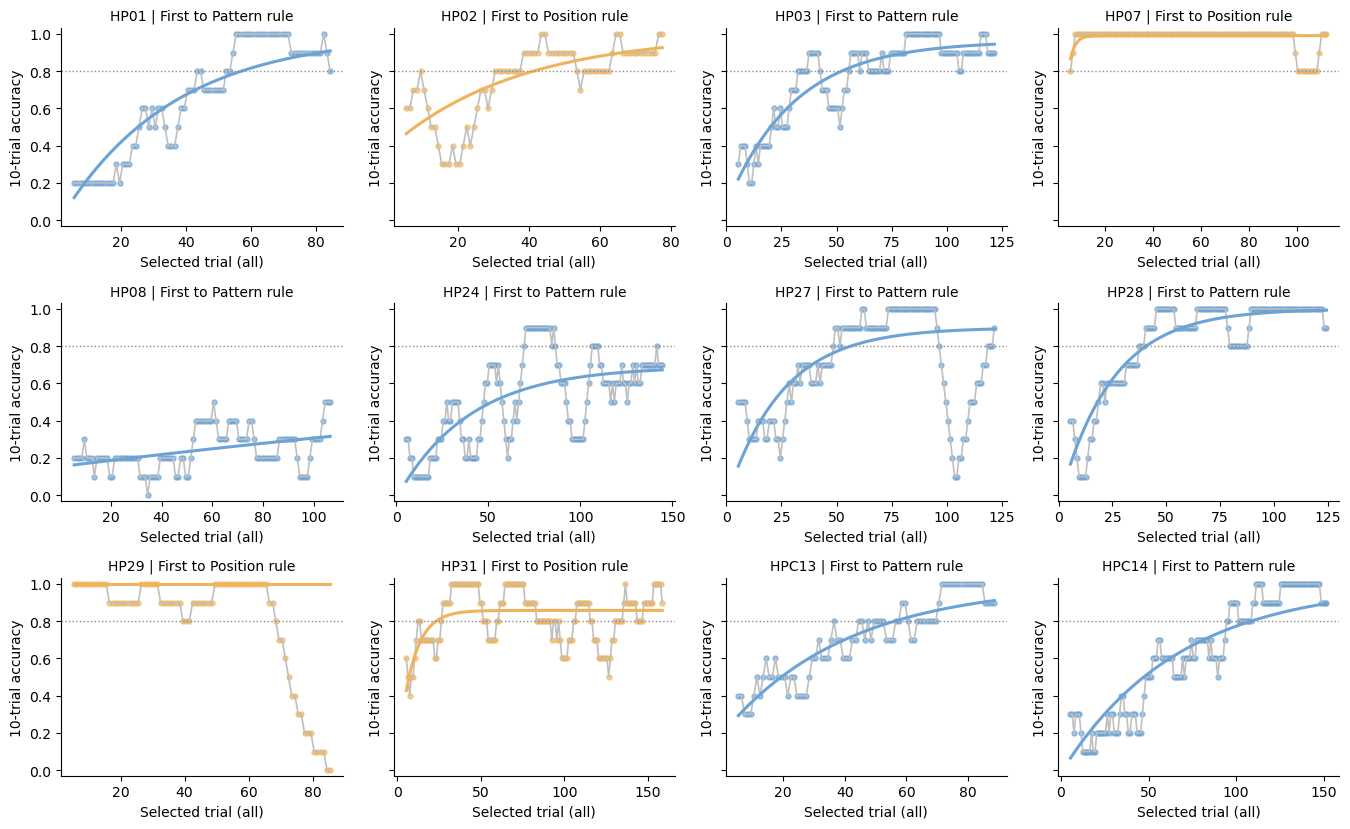

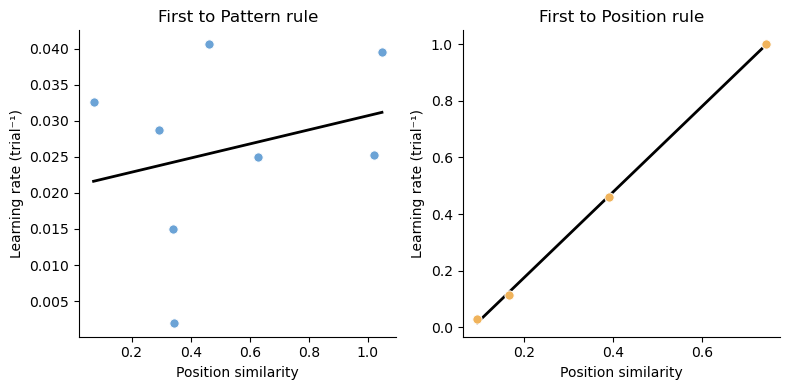

,target_task,n_session,valid,slope,intercept,r,r2,p,spearman_rho,spearman_p
0,first_pattern,8,True,0.009781,0.020919,0.268226,0.071945,0.520678,0.142857,0.735765
1,first_position,4,True,1.515798,-0.129405,0.999750,0.999501,0.000250,1.000000,0.000000


In [56]:
learning_curve_figure = plot_learning_curves(result)
similarity_learning_figure = plot_similarity_learning_relation(
    result,
    x_metric=PLOT_X,
    y_metric=PLOT_Y,
)
